# 02 - Synthetic spike-train generation (calibrated on real primate data)

**Goal:** create the synthetic dataset used for the CSIT 750 assignment (part c) and, later, for the thesis experiments.

**How it works (plain language)**
1. Load the real tuning table from notebook 01 (`results/tables/primate_tuning_curves.csv`).
2. Fit a cosine curve to every real neuron: baseline rate, tuning strength, preferred direction.
3. Build a synthetic population by copying those real baseline and strength values.
4. Simulate 8-direction reaching trials and convert firing rates into 0/1 spikes.

All the logic lives in `src/generate_data.py`; this notebook just runs it and checks the result.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repository root whether the notebook is started from the root or from notebooks/
REPO_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "src"))

import generate_data as gd

print("Repository root:", REPO_ROOT)
print("Calibration file exists:", gd.DEFAULT_CALIBRATION_CSV.exists())

Repository root: /tmp/gen
Calibration file exists: True


## Step 1 - Fit cosine tuning to the real units

In [2]:
calibration = gd.fit_cosine_tuning()
print(len(calibration), "real units")
calibration.head(10)

103 real units


,channel,unit,baseline_hz,amplitude_hz,pref_dir_rad,r2
0,1,1,44.49750,10.097759,3.190417,0.691411
1,4,1,24.69625,2.092127,0.613052,0.401939
2,5,1,3.95125,0.530150,4.904524,0.185736
3,6,1,6.52750,0.645586,2.605818,0.102163
4,8,1,3.72500,1.027168,6.111379,0.395841
5,9,1,21.40500,4.948862,4.221663,0.775561
6,9,2,0.00000,0.000000,0.000000,NaN
7,10,1,4.39500,1.139425,5.624306,0.686598
8,11,1,7.91750,1.008009,2.113636,0.252943
9,11,2,0.11875,0.024260,0.060402,0.075244


In [3]:
# Summary of what the real data looks like
print(calibration[["baseline_hz", "amplitude_hz", "r2"]].describe().round(2))
print()
print("Units with baseline < 0.5 Hz (too quiet to use as templates):",
      int((calibration["baseline_hz"] < 0.5).sum()))
print("Units where a cosine explains > 50% of the variation:",
      int((calibration["r2"] > 0.5).sum()), "of", int(calibration["r2"].notna().sum()))

       baseline_hz  amplitude_hz      r2
count       103.00        103.00  100.00
mean          9.56          2.42    0.61
std          12.88          3.23    0.24
min           0.00          0.00    0.03
25%           1.73          0.45    0.40
50%           5.51          1.28    0.65
75%          10.04          2.94    0.77
max          76.36         17.76    0.98

Units with baseline < 0.5 Hz (too quiet to use as templates): 16
Units where a cosine explains > 50% of the variation: 71 of 100


## Step 2 - Generate one dataset

Settings live in `GeneratorConfig`. Change `n_channels`, `trials_per_direction` or `seed` below and re-run.
The same seed always gives exactly the same data.

In [4]:
cfg = gd.GeneratorConfig(n_channels=96, trials_per_direction=100, seed=0)
data = gd.generate_dataset(cfg, calibration=calibration)

print("spikes shape (trials, channels, time bins):", data["spikes"].shape)
print("values present:", np.unique(data["spikes"]))
print("trials per split  train/val/test:",
      len(data["train_idx"]), len(data["val_idx"]), len(data["test_idx"]))
print("trials per direction in test set:", np.bincount(data["labels"][data["test_idx"]]))
print("silent channels:", int(data["is_silent"].sum()), "of", cfg.n_channels)

spikes shape (trials, channels, time bins): (800, 96, 100)
values present: [0 1]
trials per split  train/val/test: 560 120 120
trials per direction in test set: [15 15 15 15 15 15 15 15]
silent channels: 20 of 96


## Step 3 - Sanity check: do the spikes carry the intended tuning?

For each neuron and direction we compare the **measured** firing rate during the movement phase with the **intended** rate from the cosine model. Points should sit on the diagonal.

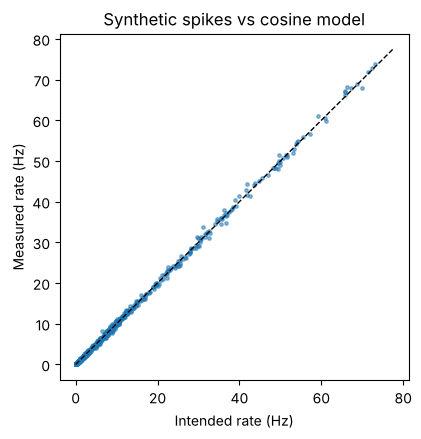

Correlation: 0.9996
Mean intended rate: 9.63 Hz | mean measured: 9.66 Hz


In [5]:
move_bins = slice(int(cfg.ramp_end_s * 1000 / cfg.bin_ms), None)
move_len_s = (cfg.n_bins - int(cfg.ramp_end_s * 1000 / cfg.bin_ms)) * cfg.dt_s
measured = np.stack([
    data["spikes"][data["labels"] == k][:, :, move_bins].sum(axis=2).mean(axis=0) / move_len_s
    for k in range(8)])                                           # (8, channels)
intended = np.stack([gd.expected_rate_hz(data, k) for k in range(8)])

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(intended.ravel(), measured.ravel(), s=6, alpha=0.5)
lim = max(intended.max(), measured.max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set_xlabel("Intended rate (Hz)"); ax.set_ylabel("Measured rate (Hz)")
ax.set_title("Synthetic spikes vs cosine model")
plt.show()

print("Correlation:", round(np.corrcoef(intended.ravel(), measured.ravel())[0, 1], 4))
print("Mean intended rate:", intended.mean().round(2), "Hz | mean measured:", measured.mean().round(2), "Hz")

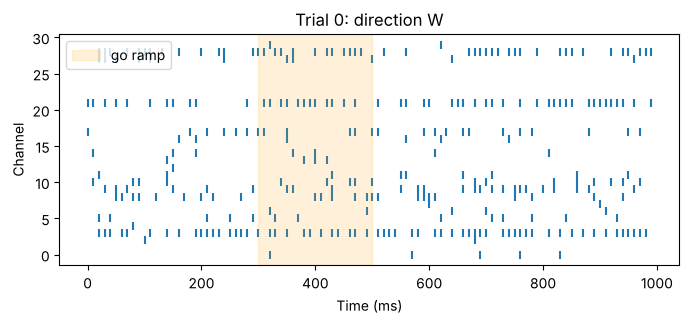

In [6]:
# Quick look at one trial: raster of the first 30 channels
trial = 0
fig, ax = plt.subplots(figsize=(8, 3))
ch, tb = np.nonzero(data["spikes"][trial, :30])
ax.scatter(tb * cfg.bin_ms, ch, marker="|", s=40)
ax.axvspan(cfg.hold_end_s * 1000, cfg.ramp_end_s * 1000, color="orange", alpha=0.15, label="go ramp")
ax.set_xlabel("Time (ms)"); ax.set_ylabel("Channel")
ax.set_title(f"Trial {trial}: direction {gd.DIRECTION_NAMES[data['labels'][trial]]}")
ax.legend(loc="upper left")
plt.show()

## Step 4 - Save datasets to disk

Files go to `data/synthetic/`. They are listed in `.gitignore` because they are large and can be re-created at any time from the seed.

In [7]:
path = gd.save_dataset(data)
print("saved:", path)

# Re-load to confirm the file round-trips
reloaded = gd.load_dataset(path)
print("round-trip identical:", np.array_equal(reloaded["spikes"], data["spikes"]))

saved: /tmp/gen/data/synthetic/synthetic_ch96_seed0.npz
round-trip identical: True


### Optional - the channel-count family used for the thesis sweep

Because the population is *nested*, the 64-channel dataset contains exactly the 32-channel neurons plus 32 more.

In [8]:
for n in [16, 32, 64, 128, 256, 512, 1024]:
    d = gd.generate_dataset(gd.GeneratorConfig(n_channels=n, trials_per_direction=100, seed=0),
                            calibration=calibration)
    print(f"{n:5d} channels -> spikes {d['spikes'].shape}")
    # gd.save_dataset(d)   # un-comment to write each one to data/synthetic/

   16 channels -> spikes (800, 16, 100)
   32 channels -> spikes (800, 32, 100)
   64 channels -> spikes (800, 64, 100)


  128 channels -> spikes (800, 128, 100)


  256 channels -> spikes (800, 256, 100)


  512 channels -> spikes (800, 512, 100)


 1024 channels -> spikes (800, 1024, 100)


## What is calibrated from real data, and what is assumed

| Part | Source |
|---|---|
| Baseline firing rates and tuning strengths | **Real** (fitted from your 103 recorded units) |
| Share of silent channels (about 17%) | **Real** (16 of 96 electrodes in the recorded session) |
| Preferred directions | Random and uniform by default (as in the proposal); `pref_dir_mode="empirical"` reuses the real ones |
| Hold / go / movement timing | **Assumed** (0.3 s hold, 0.2 s ramp, 0.5 s movement) |
| Trial-to-trial gain noise | **Assumed** (`trial_gain_sigma = 0.15`) |

Report this split honestly in the assignment and thesis.